# Phase 4e: Robustness

**Date:** 2026-11-04  
**Driver:** `code/R/04e_robustness.R --date 2026-11-04`  
**Results:** `results/2026-11-04/robustness/`

**AI measure:** `ai_dc_per1000` is **private data-center jobs per 1,000 workers**: QCEW NAICS 518210, private ownership only, over all covered jobs, times 1,000. "AI" in this notebook is shorthand for this measure. Government 518210 rows exist but are left out of the main measure; see `EXPERIMENTS.md` §0 item 24.

**Status:** A1-A8, P1 and P2 are done. Stretch goals are not run yet; that section is added when they are.

**Reading the results:** coefficients are associations. Nothing here identifies a causal effect, and the placebo below is a direct warning about reverse timing.

In [1]:
import pandas as pd
from IPython.display import display, Image
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 60)
DATE = '2026-11-04'
R = f'../results/{DATE}/robustness/'
d = pd.read_csv(R + 'robustness.csv')
AI = 'ai_dc_per1000_lag1'
COLS = ['spec', 'outcome', 'coef', 'estimate', 'se', 'pval', 'ci_lo', 'ci_hi', 'N']
def show(specs, coef=None, cols=COLS):
    x = d[d.spec.isin(specs)]
    if coef is not None: x = x[x.coef.isin(coef)]
    display(x[cols].round(4))
print(d.status.value_counts().to_dict())

{'ok': 175, 'NOT_RUN': 3}


## What each check guards against

| Check | What could go wrong that it tests |
|---|---|
| Swap the outcome (A1) | The result depends on how renewables or energy use are measured |
| Drop 2020, AK and HI, VA (A3) | One unusual year or a few unusual states drive the result |
| Border W in the SLX (A4) | The spillover depends on how "neighbor" is defined |
| RPS control (A5) | Renewable mandates, not AI, explain the pattern |
| All-ownership AI | Leaving out government jobs changes the answer |
| Placebo, AI(t+1) (A6) | AI "predicts" the past: a pre-trend or reverse timing |
| Driscoll-Kraay and Conley SEs (A7, A8) | Standard errors are too small because shocks are shared across states. Sensitivity only; clustered SEs remain the basis for conclusions |
| Distributed lags (P1) | The association takes more than a year to appear |
| Long difference (P2) | Year-to-year noise hides a long-run association |

## Gate

Before any new model, the driver reproduces the stored 4b and 4d estimates and stops if they don't match.

In [2]:
g = pd.read_csv(R + 'gate.csv')
print(f"Gate: {int(g.ok.sum())} of {len(g)} checks match within 1e-8")

Gate: 18 of 18 checks match within 1e-8


## Specification curve

Filled markers have p < 0.05. Clustered SEs unless the row names another.

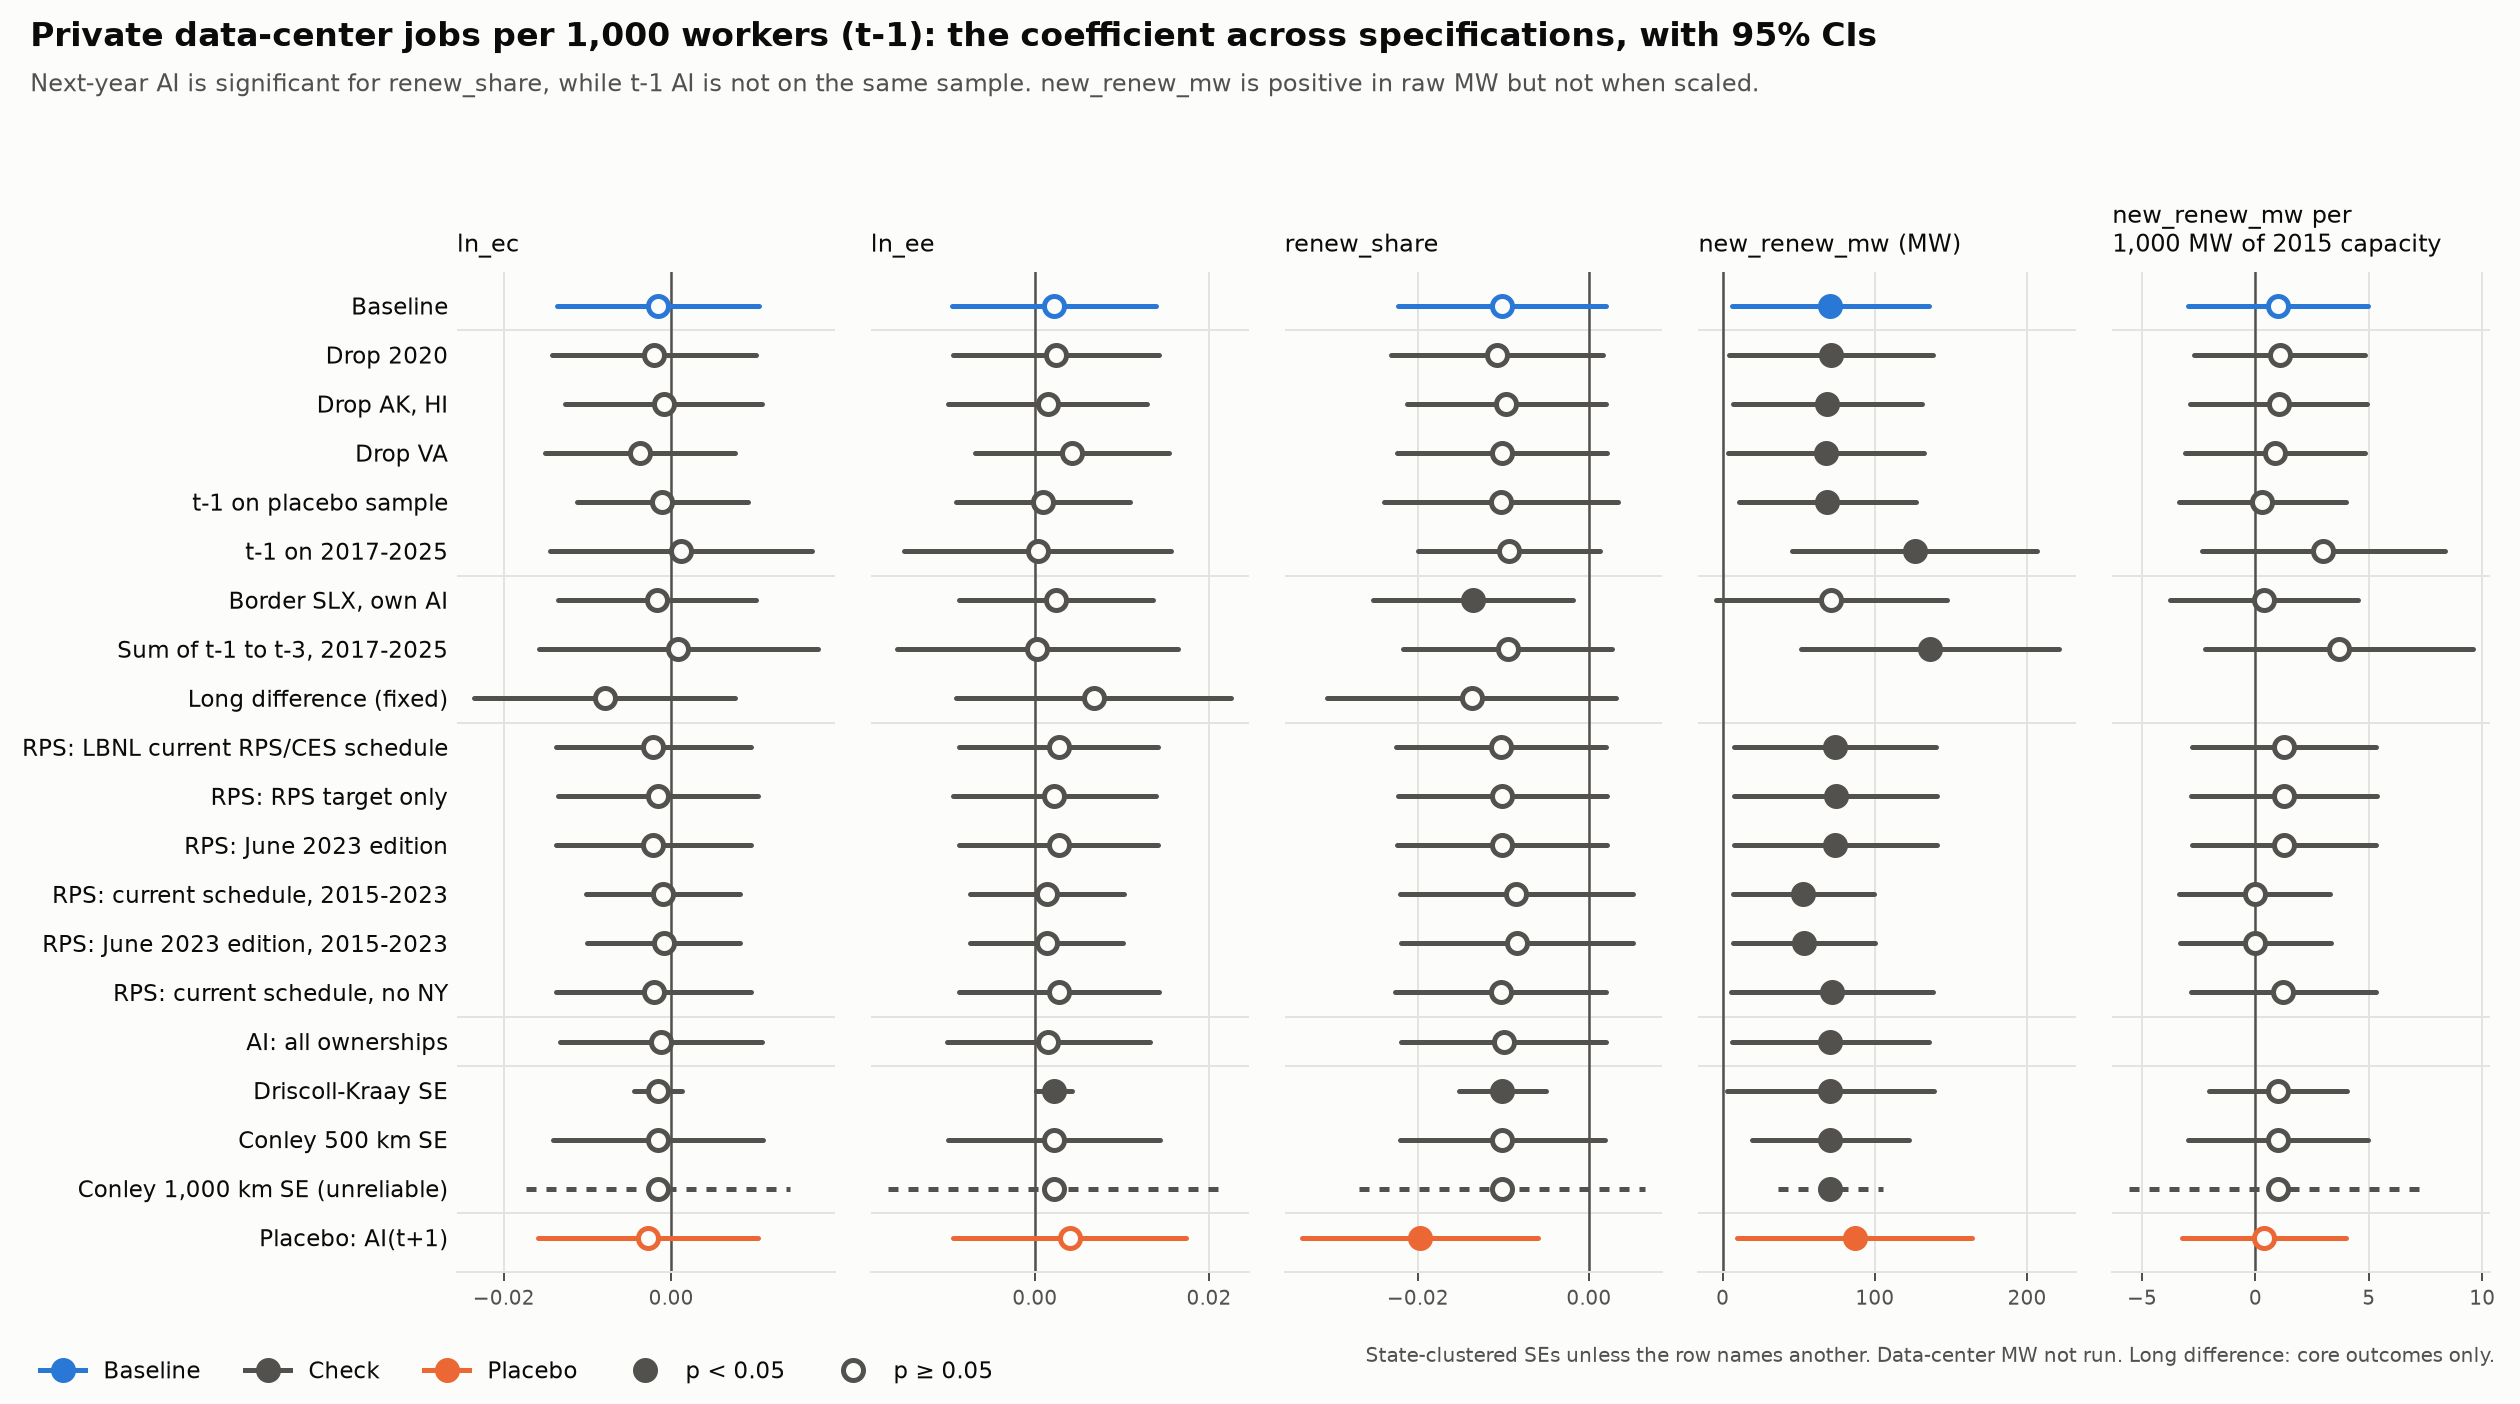

outcome,ln_ec,ln_ee,renew_share,new_renew_mw,new_renew_per_1000mw
spec_label,,,,,
Baseline,0.795,0.707,0.100,0.033,0.616
Drop 2020,0.741,0.681,0.087,0.038,0.570
"Drop AK, HI",0.880,0.795,0.101,0.031,0.599
Drop VA,0.517,0.447,0.104,0.039,0.668
t-1 on placebo sample,0.838,0.853,0.137,0.021,0.870
t-1 on 2017-2025,0.881,0.967,0.084,0.003,0.267
"Border SLX, own AI",0.780,0.658,0.025,0.065,0.853
"Sum of t-1 to t-3, 2017-2025",0.917,0.972,0.124,0.002,0.217
Long difference (fixed),0.310,0.391,0.110,NaN,NaN


In [3]:
display(Image(f'../results/{DATE}/figures/04e_spec_curve.png', width=1000))
sc = pd.read_csv(R + 'spec_curve.csv')
display(sc[sc.status == 'ok'].pivot(index='spec_label', columns='outcome', values='pval').reindex(sc[sc.status == 'ok'].spec_label.drop_duplicates())[['ln_ec', 'ln_ee', 'renew_share', 'new_renew_mw', 'new_renew_per_1000mw']].round(3))

## A5: RPS control, using the LBNL current RPS/CES schedule

`target_pct` is the larger of the RPS and CES targets each year, from LBNL's June 2026 file. LBNL revises past years between editions, and its achievement file has no target levels, so these values can't show what earlier law required at the time (`data/receipts/lbnl_rps.md`).

**Result:** the AI coefficient barely moves in any version, and the control itself is never significant at 5%. `EXPERIMENTS.md` expected the coefficient to shrink; it didn't. The 2023 edition gives nearly the same answer as the current schedule, so LBNL's revisions don't matter here. Results weaken for renew_share on 2015-2023 under both editions, so that comes from the years, not the edition.

In [4]:
show(['base', 'rps', 'rps-rpsonly', 'rps-ed2023', 'rps-to2023', 'rps-ed2023-to2023', 'rps-noNY'], [AI])
x = d[d.spec.str.startswith('rps') & (d.coef != AI)]
display(x[['spec', 'outcome', 'coef', 'estimate', 'se', 'pval', 'N']].round(5))

,spec,outcome,coef,estimate,se,pval,ci_lo,ci_hi,N
0,base,ln_ec,ai_dc_per1000_lag1,-0.0016,0.0060,0.7946,-0.0136,0.0105,550.0
1,base,ln_ee,ai_dc_per1000_lag1,0.0022,0.0058,0.7073,-0.0095,0.0139,550.0
2,base,renew_share,ai_dc_per1000_lag1,-0.0101,0.0060,0.1002,-0.0223,0.0020,550.0
3,base,new_renew_mw,ai_dc_per1000_lag1,70.8444,32.3400,0.0333,5.8547,135.8341,550.0
4,base,new_renew_per_1000mw,ai_dc_per1000_lag1,0.9962,1.9762,0.6165,-2.9751,4.9675,550.0
40,rps,ln_ec,ai_dc_per1000_lag1,-0.0021,0.0058,0.7191,-0.0138,0.0096,550.0
42,rps-rpsonly,ln_ec,ai_dc_per1000_lag1,-0.0016,0.0060,0.7875,-0.0136,0.0103,550.0
44,rps-ed2023,ln_ec,ai_dc_per1000_lag1,-0.0021,0.0058,0.7132,-0.0138,0.0095,550.0
46,rps-ed2023-to2023,ln_ec,ai_dc_per1000_lag1,-0.0009,0.0046,0.8436,-0.0101,0.0082,450.0
48,rps-to2023,ln_ec,ai_dc_per1000_lag1,-0.0009,0.0046,0.8373,-0.0101,0.0082,450.0


,spec,outcome,coef,estimate,se,pval,N
41,rps,ln_ec,target_pct,0.00055,0.00086,0.52569,550.0
43,rps-rpsonly,ln_ec,rps_target_pct,0.00007,0.00073,0.92543,550.0
45,rps-ed2023,ln_ec,target_pct_ed2023,0.00058,0.00085,0.49739,550.0
47,rps-ed2023-to2023,ln_ec,target_pct_ed2023,-0.00001,0.00071,0.98451,450.0
49,rps-to2023,ln_ec,target_pct,0.00003,0.00070,0.96587,450.0
51,rps-noNY,ln_ec,target_pct,0.00052,0.00088,0.55834,539.0
53,rps,ln_ee,target_pct,-0.00052,0.00085,0.54559,550.0
55,rps-rpsonly,ln_ee,rps_target_pct,-0.00007,0.00073,0.92498,550.0
57,rps-ed2023,ln_ee,target_pct_ed2023,-0.00055,0.00085,0.52071,550.0
59,rps-ed2023-to2023,ln_ee,target_pct_ed2023,0.00006,0.00072,0.93580,450.0


### Flag: 3 rows where LBNL's two files conflict

In these state-years the schedule shows a target above 0, but the Target Achievement file reports no obligation ("-"). They stay in the main version as LBNL publishes them. For NY 2015-2016, LBNL's achievement figures cover only Tier 1 of the current standard. The no-NY check removes NY's rows; MT 2020 stays in every version.

In [5]:
r = pd.read_csv('../data/lbnl_rps_targets.csv')
display(r[r.obligation_check.str.startswith('conflict')][['state', 'year', 'target_pct', 'ta_status', 'obligation_check', 'target_basis']])
print(r.obligation_check.value_counts().to_string())

,state,year,target_pct,ta_status,obligation_check,target_basis
291,MT,2020,15.0000,no_obligation,conflict_target_but_no_obligation,LBNL current RPS/CES schedule
374,NY,2015,38.3617,no_obligation,conflict_target_but_no_obligation,LBNL current RPS/CES schedule
375,NY,2016,38.4595,no_obligation,conflict_target_but_no_obligation,LBNL current RPS/CES schedule


obligation_check
obligation_confirmed                 294
zero_no_policy                       209
not_checkable                         30
zero_consistent                       24
conflict_target_but_no_obligation      3
zero_not_checkable                     1


## All-ownership AI

The main measure stays private only. This row adds published government 518210 jobs. Suppressed government rows count as 0, so the counts are lower bounds. Published government rows also jump from 5 in 2021 to 16 in 2022, as suppressed rows fall from 25 to 13. That is a coverage change, not new jobs.

**Result:** nearly identical to the baseline on all four outcomes.

In [6]:
show(['base'], [AI]); show(['allown'])
display(pd.read_csv('../logs/2026-11-04/gov_518210_shares.csv').head(8)[['state', 'private_jobs', 'gov_jobs', 'federal', 'state_gov', 'local', 'gov_share_pct', 'peak_year', 'peak_share_pct']])

,spec,outcome,coef,estimate,se,pval,ci_lo,ci_hi,N
0,base,ln_ec,ai_dc_per1000_lag1,-0.0016,0.0060,0.7946,-0.0136,0.0105,550.0
1,base,ln_ee,ai_dc_per1000_lag1,0.0022,0.0058,0.7073,-0.0095,0.0139,550.0
2,base,renew_share,ai_dc_per1000_lag1,-0.0101,0.0060,0.1002,-0.0223,0.0020,550.0
3,base,new_renew_mw,ai_dc_per1000_lag1,70.8444,32.3400,0.0333,5.8547,135.8341,550.0
4,base,new_renew_per_1000mw,ai_dc_per1000_lag1,0.9962,1.9762,0.6165,-2.9751,4.9675,550.0


,spec,outcome,coef,estimate,se,pval,ci_lo,ci_hi,N
100,allown,ln_ec,ai_allown_lag1_w,-0.0012,0.0060,0.8407,-0.0133,0.0109,550.0
101,allown,ln_ee,ai_allown_lag1_w,0.0016,0.0058,0.7893,-0.0101,0.0132,550.0
102,allown,renew_share,ai_allown_lag1_w,-0.0100,0.0060,0.1016,-0.0220,0.0020,550.0
103,allown,new_renew_mw,ai_allown_lag1_w,70.7922,32.1583,0.0325,6.1677,135.4167,550.0


,state,private_jobs,gov_jobs,federal,state_gov,local,gov_share_pct,peak_year,peak_share_pct
0,NM,7761.0,2530.0,0.0,0.0,2530.0,24.58,2015,30.94
1,MN,74010.0,8489.0,0.0,0.0,8489.0,10.29,2019,13.85
2,PA,124679.0,13009.0,13009.0,0.0,0.0,9.45,2016,11.81
3,OH,103085.0,6587.0,0.0,0.0,6587.0,6.01,2015,8.01
4,ND,4898.0,172.0,0.0,0.0,172.0,3.39,2024,13.67
5,AR,31693.0,641.0,0.0,637.0,4.0,1.98,2024,3.78
6,WV,12583.0,194.0,0.0,194.0,0.0,1.52,2022,3.80
7,VA,164154.0,2176.0,0.0,1332.0,844.0,1.31,2022,2.85


## A6: Placebo, AI(t+1)

Next year's AI can't affect this year's outcomes, so the coefficient should be about zero.

**Result: it fails for renew_share.** AI(t+1) is significant (-0.0197, p = 0.006). With lead and lag in one model, the lead keeps the effect (-0.0210, p = 0.007) and the lag is about zero (0.0015, p = 0.827). This holds without winsorizing the lead (p = 0.003). So the negative renew_share association can't be read as AI(t-1) lowering the share: states' renewable shares were already moving before the AI change, or the timing runs the other way.

For new_renew_mw it's less clear: p = 0.028, but p = 0.087 without winsorizing, and neither term is significant in one model. Within-state corr(lead, lag) = 0.716, so one-model tests have limited power.

In [7]:
show(['placebo', 'placebo-compare', 'placebo-nowins', 'placebo-joint'])

,spec,outcome,coef,estimate,se,pval,ci_lo,ci_hi,N
104,placebo,ln_ec,ai_lead1_w,-0.0028,0.0065,0.6729,-0.0159,0.0103,496.0
105,placebo-compare,ln_ec,ai_dc_per1000_lag1,-0.0010,0.0051,0.8380,-0.0112,0.0091,496.0
106,placebo-nowins,ln_ec,ai_dc_per1000_lead1,-0.0037,0.0059,0.5309,-0.0157,0.0082,496.0
107,placebo-joint,ln_ec,ai_lead1_w,-0.0036,0.0070,0.6146,-0.0177,0.0106,496.0
108,placebo-joint,ln_ec,ai_dc_per1000_lag1,0.0010,0.0050,0.8501,-0.0092,0.0111,496.0
109,placebo,ln_ee,ai_lead1_w,0.0040,0.0067,0.5509,-0.0094,0.0174,496.0
110,placebo-compare,ln_ee,ai_dc_per1000_lag1,0.0009,0.0050,0.8534,-0.0091,0.0109,496.0
111,placebo-nowins,ln_ee,ai_dc_per1000_lead1,0.0047,0.0059,0.4337,-0.0072,0.0166,496.0
112,placebo-joint,ln_ee,ai_lead1_w,0.0060,0.0081,0.4618,-0.0103,0.0224,496.0
113,placebo-joint,ln_ee,ai_dc_per1000_lag1,-0.0025,0.0056,0.6632,-0.0137,0.0088,496.0


## P1 and P2: Dynamics

**P1 (distributed lags, 2017-2025):** the sum of t-1 to t-3 is null for ln_ec and ln_ee, negative but not significant for renew_share (-0.0095, p = 0.124), and positive for new_renew_mw in raw MW (136.3, p = 0.002). Scaled by capacity it isn't significant (3.68, p = 0.217).

**P2 (corrected long difference, N = 50):** no core outcome is significant with HC1 SEs. renew_share is -0.0137 (p = 0.110).

In [8]:
show(['distlag', 'distlag-compare'])
show(['longdiff', 'longdiff-4b-bug'], cols=['spec', 'outcome', 'coef', 'estimate', 'se', 'pval', 'N', 'vcov_type'])

,spec,outcome,coef,estimate,se,pval,ci_lo,ci_hi,N
144,distlag,ln_ec,ai_dc_per1000_lag1,0.0040,0.0078,0.6088,-0.0117,0.0198,450.0
145,distlag,ln_ec,ai_l2,-0.0023,0.0038,0.5387,-0.0099,0.0053,450.0
146,distlag,ln_ec,ai_l3,-0.0008,0.0049,0.8678,-0.0107,0.0090,450.0
147,distlag,ln_ec,sum_lag1to3,0.0009,0.0083,0.9168,-0.0158,0.0175,450.0
148,distlag-compare,ln_ec,ai_dc_per1000_lag1,0.0012,0.0078,0.8805,-0.0144,0.0168,450.0
149,distlag,ln_ee,ai_dc_per1000_lag1,-0.0002,0.0081,0.9800,-0.0166,0.0162,450.0
150,distlag,ln_ee,ai_l2,0.0009,0.0032,0.7823,-0.0055,0.0073,450.0
151,distlag,ln_ee,ai_l3,-0.0004,0.0057,0.9444,-0.0118,0.0110,450.0
152,distlag,ln_ee,sum_lag1to3,0.0003,0.0080,0.9717,-0.0159,0.0164,450.0
153,distlag-compare,ln_ee,ai_dc_per1000_lag1,0.0003,0.0076,0.9672,-0.0150,0.0156,450.0


,spec,outcome,coef,estimate,se,pval,N,vcov_type
169,longdiff,ln_ec,dAI_2014_2024,-0.0079,0.0077,0.3102,50.0,HC1
170,longdiff,ln_ec,dAI_2014_2024,-0.0079,0.0088,0.3717,50.0,classical
171,longdiff-4b-bug,ln_ec,dAI_as_run,-0.0086,0.0089,0.3418,46.0,classical (mislabeled HC0)
172,longdiff,ln_ee,dAI_2014_2024,0.0068,0.0078,0.3914,50.0,HC1
173,longdiff,ln_ee,dAI_2014_2024,0.0068,0.0104,0.5161,50.0,classical
174,longdiff-4b-bug,ln_ee,dAI_as_run,0.0076,0.0091,0.4065,46.0,classical (mislabeled HC0)
175,longdiff,renew_share,dAI_2014_2024,-0.0137,0.0084,0.1095,50.0,HC1
176,longdiff,renew_share,dAI_2014_2024,-0.0137,0.0113,0.2329,50.0,classical
177,longdiff-4b-bug,renew_share,dAI_as_run,-0.0166,0.0117,0.1629,46.0,classical (mislabeled HC0)


## A7 and A8: Other standard errors (sensitivity only)

Driscoll-Kraay SEs tend to be too small with T = 11. Conley at 1,000 km isn't positive definite for any outcome, so those rows are unreliable.

In [9]:
show(['dk', 'conley500', 'conley1000'], cols=['spec', 'outcome', 'estimate', 'se', 'pval', 'note'])
display(pd.read_csv(R + 'conley_vcov_check.csv').round(4))

,spec,outcome,estimate,se,pval,note
129,dk,ln_ec,-0.0016,0.0013,0.2462,sensitivity only; T=11
130,dk,ln_ee,0.0022,0.0009,0.0357,sensitivity only; T=11
131,dk,renew_share,-0.0101,0.0023,0.0013,sensitivity only; T=11
132,dk,new_renew_mw,70.8444,30.5581,0.0429,sensitivity only; T=11
133,dk,new_renew_per_1000mw,0.9962,1.3720,0.4844,sensitivity only; T=11
134,conley500,ln_ec,-0.0016,0.0064,0.8067,check only
135,conley500,ln_ee,0.0022,0.0062,0.7218,check only
136,conley500,renew_share,-0.0101,0.0061,0.0967,check only
137,conley500,new_renew_mw,70.8444,26.3391,0.0074,check only
138,conley500,new_renew_per_1000mw,0.9962,2.0177,0.6217,check only


,outcome,cutoff_km,min_eigenvalue,not_pd,se_raw,se_fixed,se_cluster
0,ln_ec,500,0.0000,False,0.0064,0.0064,0.0060
1,ln_ee,500,0.0000,False,0.0062,0.0062,0.0058
2,renew_share,500,0.0000,False,0.0061,0.0061,0.0060
3,new_renew_mw,500,226.2651,False,26.3391,26.3391,32.3400
4,new_renew_per_1000mw,500,0.4931,False,2.0177,2.0177,1.9762
5,ln_ec,1000,-0.0174,True,0.0074,0.0080,0.0060
6,ln_ee,1000,-0.1012,True,0.0083,0.0097,0.0058
7,renew_share,1000,-0.0001,True,0.0057,0.0085,0.0060
8,new_renew_mw,1000,-111.2634,True,14.3638,17.5545,32.3400
9,new_renew_per_1000mw,1000,-162.7677,True,2.2179,3.3336,1.9762


## Not run

Data-center MW (A2): no state-year series exists.

## Stretch goals

Not run yet.

In [10]:
display(d[d.status != 'ok'][['spec', 'outcome', 'status', 'note']])

,spec,outcome,status,note
7,swapAI-dcmw,ln_ec,NOT_RUN,not available: Phase 2 built no state-year data-center M...
8,swapAI-dcmw,ln_ee,NOT_RUN,not available: Phase 2 built no state-year data-center M...
9,swapAI-dcmw,renew_share,NOT_RUN,not available: Phase 2 built no state-year data-center M...
